# Comparative Implementation of Machine Learning Regression Algorithms
### Programming and Experimental Evaluation on the California Housing Dataset

## 1. Introduction

**Objective.** This notebook implements six regression algorithms, trains them on the *same* training data, evaluates them on the *same* held-out test data, and compares them using MAE, MSE, RMSE and R². All results, tables, plots, the discussion and the final conclusion are generated by code from the actual experiment; nothing is hard-coded.

**What is regression?** Regression is a supervised learning task in which a model learns a mapping from input features to a *continuous numerical* target (here, the median house value of a district). This differs from classification, where the target is a discrete class label.

**Why compare several algorithms on one dataset?** No single algorithm is best for every problem. Different algorithms make different assumptions (linearity, local similarity, hierarchical splits, additive ensembles, layered non-linear transformations). Evaluating them under identical conditions (same data, same split, same metrics) makes the comparison fair and shows how model assumptions, flexibility and complexity affect predictive performance.

**Algorithms evaluated**

| # | Algorithm | Core idea |
|---|-----------|-----------|
| 1 | Linear Regression | Fits a linear combination of the features by minimising squared error |
| 2 | Decision Tree Regression | Recursively splits the feature space; each leaf predicts the mean target of its samples |
| 3 | Random Forest Regression | Averages many decorrelated trees trained on bootstrap samples |
| 4 | Neural Network (MLP) Regression | Layers of weighted sums and non-linear activations trained by backpropagation |
| 5 | XGBoost Regression | Gradient boosting: trees are added sequentially to correct the current errors |
| 6 | K-Nearest Neighbors Regression | Predicts the average target of the K most similar training samples |

## 2. Import Libraries

The next cell checks whether **XGBoost** is installed and installs it with `pip` only if it is missing (no manual step is needed). XGBoost is a required algorithm in this assignment and is never skipped or replaced.

In [1]:
# --- XGBoost installation check (installs only if the package is missing) ---
import importlib
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("xgboost") is None:
    print("XGBoost not found. Installing it with pip ...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "xgboost"])
    importlib.invalidate_caches()
else:
    print("XGBoost is already installed.")

XGBoost is already installed.


In [2]:
import time
import warnings
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

import sklearn
import xgboost
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

# ---- Global reproducibility / experiment settings ----
RANDOM_STATE = 42     # seed used for the split and every stochastic model
TEST_SIZE = 0.20      # 80:20 train/test split
np.random.seed(RANDOM_STATE)

# ---- Plot styling ----
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 12, "axes.labelsize": 10})
pd.set_option("display.max_columns", None)

print(f"Python        : {platform.python_version()}")
print(f"NumPy         : {np.__version__}")
print(f"Pandas        : {pd.__version__}")
print(f"scikit-learn  : {sklearn.__version__}")
print(f"XGBoost       : {xgboost.__version__}")

Python        : 3.13.18
NumPy         : 2.4.6
Pandas        : 2.2.3
scikit-learn  : 1.6.1
XGBoost       : 3.4.1


## 3. Load and Explore the Dataset

The **California Housing** dataset (Pace & Barry, 1997; derived from the 1990 U.S. Census) contains **20,640 samples**. Each row describes one census *block group* (a small geographic district) in California.

**Input features (8)**

| Feature | Meaning |
|---------|---------|
| `MedInc` | Median household income in the block group (in tens of thousands of USD) |
| `HouseAge` | Median age of houses in the block group (years) |
| `AveRooms` | Average number of rooms per household |
| `AveBedrms` | Average number of bedrooms per household |
| `Population` | Number of residents in the block group |
| `AveOccup` | Average number of household members (occupancy) |
| `Latitude` | Latitude of the block group |
| `Longitude` | Longitude of the block group |

**Target:** `MedHouseVal` is the median house value of the block group, expressed in units of **\$100,000**. A target value of `2.5` therefore corresponds to **\$250,000**.

The dataset is loaded with `fetch_california_housing(as_frame=True)`. (It is downloaded automatically on first use, so an internet connection is needed the first time.)

In [3]:
housing = fetch_california_housing(as_frame=True)
df = housing.frame.copy()

TARGET = "MedHouseVal"
X = df.drop(columns=TARGET)   # all 8 original features, unmodified
y = df[TARGET]                # target (not scaled, not transformed)

assert X.shape[1] == 8, "Expected exactly 8 original features"

print("Full dataset shape      :", df.shape)
print("Feature matrix X shape  :", X.shape)
print("Target vector y shape   :", y.shape)
print("Feature names           :", list(X.columns))
print("Target name             :", TARGET)

Full dataset shape      : (20640, 9)
Feature matrix X shape  : (20640, 8)
Target vector y shape   : (20640,)
Feature names           : ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
Target name             : MedHouseVal


In [4]:
# First five rows
display(df.head())

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [5]:
# Descriptive statistics (transposed for readability)
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


In [6]:
# Missing-value check
missing = df.isna().sum()
display(missing.to_frame("Missing values").T)
print("Total missing values in the dataset:", int(missing.sum()))

# The target in this dataset is known to be capped (censored) at its maximum value.
n_at_max = int((y == y.max()).sum())
print(f"\nTarget range: {y.min():.3f} to {y.max():.3f}  (units of USD 100,000)")
print(f"Number of block groups at the maximum target value: {n_at_max} "
      f"({100 * n_at_max / len(y):.2f}% of the data)")

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
Missing values,0,0,0,0,0,0,0,0,0


Total missing values in the dataset: 0

Target range: 0.150 to 5.000  (units of USD 100,000)
Number of block groups at the maximum target value: 965 (4.68% of the data)


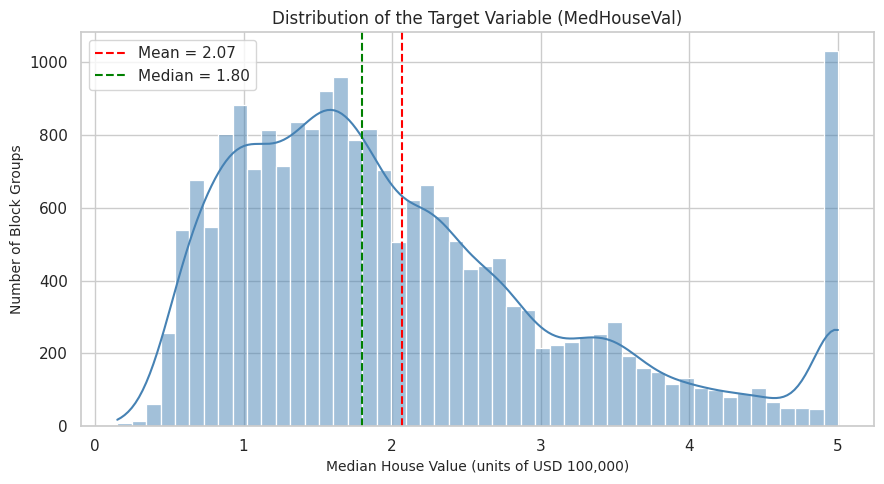

In [7]:
# Target distribution
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(y, bins=50, kde=True, color="steelblue", ax=ax)
ax.axvline(y.mean(), color="red", linestyle="--", label=f"Mean = {y.mean():.2f}")
ax.axvline(y.median(), color="green", linestyle="--", label=f"Median = {y.median():.2f}")
ax.set_title("Distribution of the Target Variable (MedHouseVal)")
ax.set_xlabel("Median House Value (units of USD 100,000)")
ax.set_ylabel("Number of Block Groups")
ax.legend()
plt.tight_layout()
plt.show()

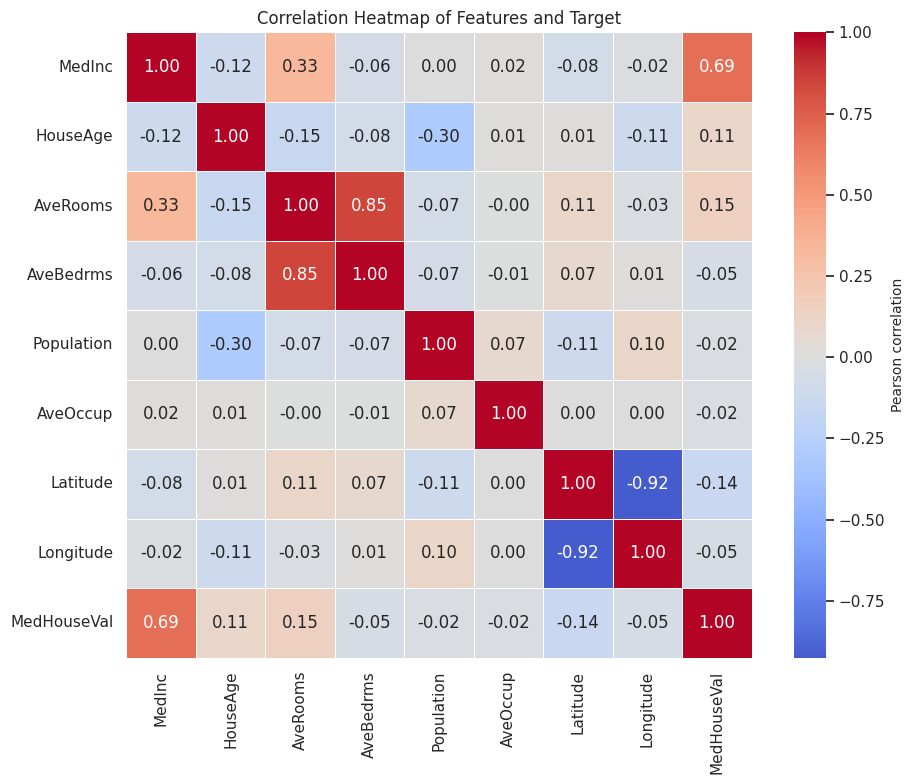

In [8]:
# Correlation heatmap (descriptive only; nothing is fitted or selected from it)
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.5, cbar_kws={"label": "Pearson correlation"})
plt.title("Correlation Heatmap of Features and Target")
plt.tight_layout()
plt.show()

**Observations.** The data has no missing values. The target is right-skewed and has a visible spike at its maximum value because house values were capped when the data was collected; this limits how well *any* model can predict the very top of the range. `MedInc` is the feature most correlated with the target. These plots are purely descriptive; no statistic from them is used to fit or select anything.

## 4. Data Preprocessing

**Decisions**

1. **All 8 original features are used.** No features are removed, created or transformed beyond scaling.
2. **Train/test split of 80:20** with `train_test_split(..., random_state=42)`. The split is done **once**, and the very same `X_train`, `X_test`, `y_train`, `y_test` are used by all six models.
3. **Test data is never used for fitting or tuning.** It is used only to generate final predictions for evaluation.
4. **Scaling without leakage.** Models that need scaling are wrapped in a scikit-learn `Pipeline` with `StandardScaler`. When `pipeline.fit(X_train, y_train)` runs, the scaler learns the mean and standard deviation from **training data only**; when `pipeline.predict(X_test)` runs, it applies those *training* statistics to the test data.
5. **The target is not scaled.** Predictions and errors therefore stay in the original units (USD 100,000).

**Which models are scaled, and why**

| Model | Scaling | Reason |
|-------|---------|--------|
| Linear Regression | StandardScaler (recommended) | Not required for the least-squares solution, but puts coefficients on a comparable scale |
| KNN | **Required** | Distance-based: a feature with a large numeric range (e.g. `Population`) would dominate the Euclidean distance |
| MLP | **Required** | Gradient-based training converges faster and more reliably when inputs have similar scales |
| Decision Tree, Random Forest, XGBoost | Not needed | Trees split on one feature at a time using thresholds, so monotonic rescaling does not change the learned splits |

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

print("X_train shape:", X_train.shape)
print("X_test  shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test  shape:", y_test.shape)
print(f"\nTrain share: {len(X_train) / len(X):.0%} | Test share: {len(X_test) / len(X):.0%}")

# Sanity checks: features and targets stay aligned and the two partitions do not overlap
assert X_train.index.equals(y_train.index) and X_test.index.equals(y_test.index)
assert set(X_train.index).isdisjoint(set(X_test.index))
assert len(X_train) + len(X_test) == len(X)
print("Split checks passed: aligned rows, no overlap between train and test.")

X_train shape: (16512, 8)
X_test  shape: (4128, 8)
y_train shape: (16512,)
y_test  shape: (4128,)

Train share: 80% | Test share: 20%
Split checks passed: aligned rows, no overlap between train and test.


## 5. Implementation of the Six Algorithms

Each model is defined below with its configuration and a short explanation. Fixed hyper-parameters are used for the main comparison; **no tuning is performed and the test set is never used to choose settings**. Training and prediction for all six models happen together in Section 6.

### 5.1 Model 1: Linear Regression

**How it works.** Linear Regression models the target as a weighted sum of the features, $\hat{y} = b_0 + b_1 x_1 + \dots + b_8 x_8$. The coefficients are estimated by **ordinary least squares**, i.e. they minimise the sum of squared differences between actual and predicted values. It can only represent a *linear* relationship between the features and the target.

**Implementation.** `StandardScaler` followed by `LinearRegression` inside a `Pipeline`. There are no hyper-parameters to set for the basic least-squares model.

In [10]:
linear_regression_model = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression()),
])
linear_regression_model

Pipeline(steps=[('scaler', StandardScaler()),
                ('regressor', LinearRegression())])

### 5.2 Model 2: Decision Tree Regression

**How it works.** A decision tree repeatedly splits the data using a feature and a threshold (e.g. `MedInc <= 5.1`), choosing at each step the split that most reduces the squared error within the resulting groups. This recursive splitting continues until a stopping rule is met. Each final **leaf** predicts a number: the *mean target value* of the training samples that fall into it.

**Configuration.** Unrestricted trees memorise the training data, so the complexity is limited:
- `max_depth=10`: caps how many consecutive splits a prediction path can have.
- `min_samples_leaf=5`: every leaf must contain at least 5 training samples.
- `random_state=42`: reproducibility (ties between equally good splits).

Original unscaled features are used.

In [11]:
decision_tree_model = DecisionTreeRegressor(
    max_depth=10,
    min_samples_leaf=5,
    random_state=RANDOM_STATE,
)
decision_tree_model

DecisionTreeRegressor(max_depth=10, min_samples_leaf=5, random_state=42)

### 5.3 Model 3: Random Forest Regression

**How it works.** A random forest trains many decision trees, each on a different **bootstrap sample** (rows drawn with replacement) and, at each split, considering only a **random subset of features**. These two sources of randomness decorrelate the trees. The forest's prediction is the **average** of all trees, which reduces the high variance of a single tree and makes the model more stable.

**Configuration.**
- `n_estimators=200`: number of trees.
- `random_state=42`: reproducibility.
- `n_jobs=-1`: use all CPU cores (affects speed only, not results).
- Other settings are scikit-learn defaults (e.g. fully grown trees, bootstrap sampling).

Original unscaled features are used.

In [12]:
random_forest_model = RandomForestRegressor(
    n_estimators=200,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
random_forest_model

RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42)

### 5.4 Model 4: Neural Network Regression (MLP)

**How it works.** A Multi-Layer Perceptron is made of layers of **neurons**. Each neuron computes a weighted sum of its inputs plus a bias and passes it through a **non-linear activation function**. Stacking **hidden layers** lets the network learn complex non-linear relationships. Training minimises a **loss** (squared error) by **backpropagation**, which computes the gradient of the loss with respect to every weight, followed by a gradient-based update (here, the **Adam** optimiser).

**Configuration.**
- `hidden_layer_sizes=(128, 64)`: two hidden layers with 128 and 64 neurons.
- `activation="relu"`, `solver="adam"`.
- `max_iter=500`: upper limit on training epochs.
- `early_stopping=True` with `validation_fraction=0.1` and `n_iter_no_change=20`: 10% of the **training** data is held out internally, and training stops when the validation score has not improved for 20 consecutive epochs. The test set is not involved.
- `random_state=42`.

`StandardScaler` is required, so the model is a `Pipeline`. Whether training stopped by the early-stopping rule or hit `max_iter` is reported from the fitted model in Section 6; it is not assumed here.

In [13]:
mlp_model = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("mlp", MLPRegressor(
        hidden_layer_sizes=(128, 64),
        activation="relu",
        solver="adam",
        max_iter=500,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=20,
        random_state=RANDOM_STATE,
    )),
])
mlp_model

Pipeline(steps=[('scaler', StandardScaler()),
                ('mlp',
                 MLPRegressor(early_stopping=True, hidden_layer_sizes=(128, 64),
                              max_iter=500, n_iter_no_change=20,
                              random_state=42))])

### 5.5 Model 5: XGBoost Regression

**How it works.** XGBoost implements **gradient boosting**. Unlike a random forest (independent trees averaged in parallel), boosting builds trees **sequentially**: it starts from an initial prediction, computes the errors (the gradient of the loss), and fits a new small tree to those remaining errors. The new tree's output, scaled by the **learning rate**, is added to the ensemble, so each tree corrects the mistakes of the ones before it. Regularisation and subsampling help control overfitting.

**Configuration.**
- `n_estimators=300`: number of boosting rounds (trees).
- `max_depth=6`: depth of each tree.
- `learning_rate=0.05`: shrinks each tree's contribution (smaller values need more trees but generalise better).
- `subsample=0.8`: each tree sees 80% of the training rows.
- `colsample_bytree=0.8`: each tree sees 80% of the features.
- `objective="reg:squarederror"`, `random_state=42`, `n_jobs=-1`.

Original unscaled features are used.

In [14]:
xgboost_model = XGBRegressor(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
xgboost_model

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=300,
             n_jobs=-1, num_parallel_tree=None, ...)

### 5.6 Model 6: K-Nearest Neighbors Regression (KNN)

**How it works.** KNN has no real training phase; it stores the training data. To predict for a new sample, it (1) computes the **Euclidean distance** from that sample to every training sample, (2) selects the **K closest** training samples, and (3) predicts the **average of their target values**.

**Why scaling is essential.** Distances are computed directly from feature values. Without scaling, a feature with a large range (such as `Population`) would dominate the distance, and small-range features (such as `AveRooms` or `MedInc`) would barely matter. `StandardScaler` puts all features on a comparable scale (fitted on training data only).

**Configuration.** `n_neighbors=5`, `weights="uniform"` (all neighbours count equally), `metric="euclidean"`.

In [15]:
knn_model = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("knn", KNeighborsRegressor(
        n_neighbors=5,
        weights="uniform",
        metric="euclidean",
    )),
])
knn_model

Pipeline(steps=[('scaler', StandardScaler()),
                ('knn', KNeighborsRegressor(metric='euclidean'))])

## 6. Model Training and Prediction

All six models are collected in one dictionary and processed by the same loop: every model is **fitted on `X_train, y_train`** and then predicts on the **same `X_test`**. For each model the notebook stores the fitted object, the test predictions (used for evaluation and plots), the training-set predictions (used only to diagnose overfitting, never to tune) and the fit time. Any warning raised during training is **displayed**, not suppressed.

In [16]:
models = {
    "Linear Regression":    linear_regression_model,
    "Decision Tree":        decision_tree_model,
    "Random Forest":        random_forest_model,
    "Neural Network (MLP)": mlp_model,
    "XGBoost":              xgboost_model,
    "KNN":                  knn_model,
}

# Summary of the configuration actually stored in each model object
KEY_PARAMS = {
    "Linear Regression":    [],
    "Decision Tree":        ["max_depth", "min_samples_leaf", "random_state"],
    "Random Forest":        ["n_estimators", "random_state"],
    "Neural Network (MLP)": ["hidden_layer_sizes", "activation", "solver", "max_iter", "early_stopping", "random_state"],
    "XGBoost":              ["n_estimators", "max_depth", "learning_rate", "subsample", "colsample_bytree", "random_state"],
    "KNN":                  ["n_neighbors", "weights", "metric"],
}

config_rows = []
for name, model in models.items():
    estimator = model[-1] if isinstance(model, Pipeline) else model
    params = estimator.get_params()
    config_rows.append({
        "Model": name,
        "Scaled (StandardScaler)": "Yes" if isinstance(model, Pipeline) else "No",
        "Key hyper-parameters": ", ".join(f"{p}={params[p]}" for p in KEY_PARAMS[name]) or "none (ordinary least squares)",
    })

with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(config_rows).set_index("Model"))

,Scaled (StandardScaler),Key hyper-parameters
Model,,
Linear Regression,Yes,none (ordinary least squares)
Decision Tree,No,"max_depth=10, min_samples_leaf=5, random_state=42"
Random Forest,No,"n_estimators=200, random_state=42"
Neural Network (MLP),Yes,"hidden_layer_sizes=(128, 64), activation=relu, solver=adam, max_iter=500, early_stopping=True, random_state=42"
XGBoost,No,"n_estimators=300, max_depth=6, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, random_state=42"
KNN,Yes,"n_neighbors=5, weights=uniform, metric=euclidean"


In [17]:
fitted_models = {}       # fitted model objects
predictions = {}         # predictions on X_test  (used for evaluation)
train_predictions = {}   # predictions on X_train (used only to check overfitting)
fit_times = {}           # training time in seconds
training_warnings = {}   # warnings raised during fitting (if any)

for name, model in models.items():
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")          # record every warning so none is hidden
        start = time.perf_counter()
        model.fit(X_train, y_train)              # same training data for every model
        fit_times[name] = time.perf_counter() - start

    fitted_models[name] = model
    predictions[name] = model.predict(X_test)    # same test data for every model
    train_predictions[name] = model.predict(X_train)
    training_warnings[name] = [f"{w.category.__name__}: {w.message}" for w in caught]

    print(f"[done] {name:<22} trained in {fit_times[name]:7.2f} s")
    for message in training_warnings[name]:
        print(f"       WARNING -> {message}")

[done] Linear Regression      trained in    0.02 s
[done] Decision Tree          trained in    0.20 s
[done] Random Forest          trained in   32.27 s
       WARNING -> DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
[done] Neural Network (MLP)   trained in   19.44 s
       WARNING -> DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
[done] XGBoost                trained in    3.37 s
       WARNING -> DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
[done] KNN                    trained in    0.03 s


In [18]:
# ---- Verification: every model used the same features, target and test set ----
expected_features = list(X.columns)
for name, model in fitted_models.items():
    used = list(getattr(model, "feature_names_in_", expected_features))
    assert used == expected_features, f"{name} used different features"
    assert len(predictions[name]) == len(y_test), f"{name}: unexpected number of test predictions"

print(f"All {len(fitted_models)} models were trained on the same 8 features: {expected_features}")
print(f"All {len(fitted_models)} models predict the same target ('{TARGET}') for the same "
      f"{len(y_test)} test observations (X_test / y_test).")

All 6 models were trained on the same 8 features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
All 6 models predict the same target ('MedHouseVal') for the same 4128 test observations (X_test / y_test).


In [19]:
# ---- MLP: report what actually happened during training (no assumptions) ----
mlp_estimator = fitted_models["Neural Network (MLP)"].named_steps["mlp"]
mlp_n_iter = mlp_estimator.n_iter_
mlp_max_iter = mlp_estimator.max_iter
mlp_stopped_early = mlp_n_iter < mlp_max_iter
mlp_convergence_warning = any("ConvergenceWarning" in m for m in training_warnings["Neural Network (MLP)"])

print(f"Epochs run                      : {mlp_n_iter} (limit = {mlp_max_iter})")
print(f"Best internal validation R2     : {mlp_estimator.best_validation_score_:.4f}")
print(f"Final training loss             : {mlp_estimator.loss_:.6f}")
print(f"ConvergenceWarning raised       : {mlp_convergence_warning}")

if mlp_stopped_early and not mlp_convergence_warning:
    print("\nResult: training stopped BEFORE max_iter because the internal validation score "
          "stopped improving (early stopping criterion met).")
else:
    print("\nResult: training reached max_iter without meeting the stopping criterion, so the "
          "network may not have fully converged. Increasing max_iter could be considered.")

Epochs run                      : 103 (limit = 500)
Best internal validation R2     : 0.8173
Final training loss             : 0.115224
ConvergenceWarning raised       : False

Result: training stopped BEFORE max_iter because the internal validation score stopped improving (early stopping criterion met).


## 7. Evaluation Metrics

All metrics are computed from the **actual test-set predictions** with `sklearn.metrics`. With $y_i$ the actual value, $\hat{y}_i$ the prediction, and $n$ the number of test samples:

| Metric | Formula | Interpretation |
|--------|---------|----------------|
| **MAE** | $\frac{1}{n}\sum \lvert y_i-\hat y_i\rvert$ | Average absolute error, in target units. Easy to interpret; treats all errors equally. |
| **MSE** | $\frac{1}{n}\sum (y_i-\hat y_i)^2$ | Average squared error, in squared units. Penalises large errors heavily. |
| **RMSE** | $\sqrt{\text{MSE}}$ | Same units as the target; sensitive to large errors. Used as the primary ranking metric. |
| **R²** | $1-\frac{\sum (y_i-\hat y_i)^2}{\sum (y_i-\bar y)^2}$ | Proportion of target variance explained by the model (1 is perfect; 0 equals always predicting the mean; it can be negative). It is **not** an accuracy percentage as in classification. |

Because the target is in units of USD 100,000, an MAE or RMSE of `0.50` means a typical error of roughly USD 50,000. **Lower** is better for MAE, MSE and RMSE; **higher** is better for R².

In [20]:
def evaluate_regression(y_true, y_pred):
    """Return the four required regression metrics for one set of predictions."""
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return {"MAE": mae, "MSE": mse, "RMSE": rmse, "R²": r2}


# Unrounded values are kept in the DataFrame; rounding is applied only when displaying.
results_df = pd.DataFrame(
    {name: evaluate_regression(y_test, pred) for name, pred in predictions.items()}
).T
results_df.index.name = "Model"
results_df = results_df.sort_values("RMSE", ascending=True)

print("Model comparison on the TEST set (sorted by RMSE, lower is better):\n")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(results_df)

Model comparison on the TEST set (sorted by RMSE, lower is better):



,MAE,MSE,RMSE,R²
Model,,,,
XGBoost,0.2993,0.2059,0.4538,0.8429
Random Forest,0.3268,0.2540,0.5040,0.8062
Neural Network (MLP),0.3484,0.2680,0.5177,0.7955
Decision Tree,0.4314,0.4076,0.6385,0.6889
KNN,0.4462,0.4324,0.6576,0.6700
Linear Regression,0.5332,0.5559,0.7456,0.5758


In [21]:
# ---- Independent check of the metric values using plain NumPy ----
y_true = y_test.to_numpy()
for name, pred in predictions.items():
    err = y_true - pred
    mae_manual = np.mean(np.abs(err))
    mse_manual = np.mean(err ** 2)
    r2_manual = 1 - np.sum(err ** 2) / np.sum((y_true - y_true.mean()) ** 2)
    assert np.isclose(mae_manual, results_df.loc[name, "MAE"])
    assert np.isclose(mse_manual, results_df.loc[name, "MSE"])
    assert np.isclose(np.sqrt(mse_manual), results_df.loc[name, "RMSE"])
    assert np.isclose(r2_manual, results_df.loc[name, "R²"])
print("Metric verification passed: sklearn values match manual NumPy calculations for all models.")

# ---- Best model for each metric (selected programmatically) ----
best_mae_model = results_df["MAE"].idxmin()
best_rmse_model = results_df["RMSE"].idxmin()
best_r2_model = results_df["R²"].idxmax()

print(f"\nLowest MAE  : {best_mae_model} ({results_df.loc[best_mae_model, 'MAE']:.4f})")
print(f"Lowest RMSE : {best_rmse_model} ({results_df.loc[best_rmse_model, 'RMSE']:.4f})")
print(f"Highest R²  : {best_r2_model} ({results_df.loc[best_r2_model, 'R²']:.4f})")

Metric verification passed: sklearn values match manual NumPy calculations for all models.

Lowest MAE  : XGBoost (0.2993)
Lowest RMSE : XGBoost (0.4538)
Highest R²  : XGBoost (0.8429)


In [22]:
# ---- Interpretation in the original target units (1 unit = USD 100,000) ----
UNIT_USD = 100_000
interp = pd.DataFrame({
    "MAE (USD)":  results_df["MAE"] * UNIT_USD,
    "RMSE (USD)": results_df["RMSE"] * UNIT_USD,
    "R²":         results_df["R²"],
})
with pd.option_context("display.float_format", "{:,.2f}".format):
    display(interp)

print("RMSE is in the same units as the target; MAE is the average absolute error. "
      "RMSE >= MAE always, and a large gap between them indicates some large individual errors.")

,MAE (USD),RMSE (USD),R²
Model,,,
XGBoost,"29,925.40","45,376.33",0.84
Random Forest,"32,681.19","50,396.02",0.81
Neural Network (MLP),"34,838.25","51,768.87",0.80
Decision Tree,"43,136.56","63,847.17",0.69
KNN,"44,615.35","65,758.77",0.67
Linear Regression,"53,320.01","74,558.14",0.58


RMSE is in the same units as the target; MAE is the average absolute error. RMSE >= MAE always, and a large gap between them indicates some large individual errors.


In [23]:
# ---- Training vs. test performance (used only to diagnose over-fitting; no tuning is done) ----
generalisation_df = pd.DataFrame({
    "Train R²":  {n: r2_score(y_train, p) for n, p in train_predictions.items()},
    "Test R²":   {n: r2_score(y_test, p) for n, p in predictions.items()},
    "Train RMSE": {n: np.sqrt(mean_squared_error(y_train, p)) for n, p in train_predictions.items()},
    "Test RMSE":  {n: np.sqrt(mean_squared_error(y_test, p)) for n, p in predictions.items()},
})
generalisation_df["R² gap (train - test)"] = generalisation_df["Train R²"] - generalisation_df["Test R²"]
generalisation_df.index.name = "Model"

with pd.option_context("display.float_format", "{:.4f}".format):
    display(generalisation_df.loc[results_df.index])

,Train R²,Test R²,Train RMSE,Test RMSE,R² gap (train - test)
Model,,,,,
XGBoost,0.9183,0.8429,0.3305,0.4538,0.0754
Random Forest,0.9742,0.8062,0.1857,0.5040,0.1680
Neural Network (MLP),0.8247,0.7955,0.4840,0.5177,0.0293
Decision Tree,0.8201,0.6889,0.4904,0.6385,0.1312
KNN,0.7969,0.6700,0.5211,0.6576,0.1269
Linear Regression,0.6126,0.5758,0.7197,0.7456,0.0368


## 8. Visualization

All plots below are generated from the real test-set predictions stored in `predictions`.

### 8.1 Actual vs. Predicted Values

Each panel plots actual against predicted test values. The dashed diagonal is the line of **perfect prediction** ($y = x$): points close to it are accurate. All panels share the same axis range for a fair visual comparison.

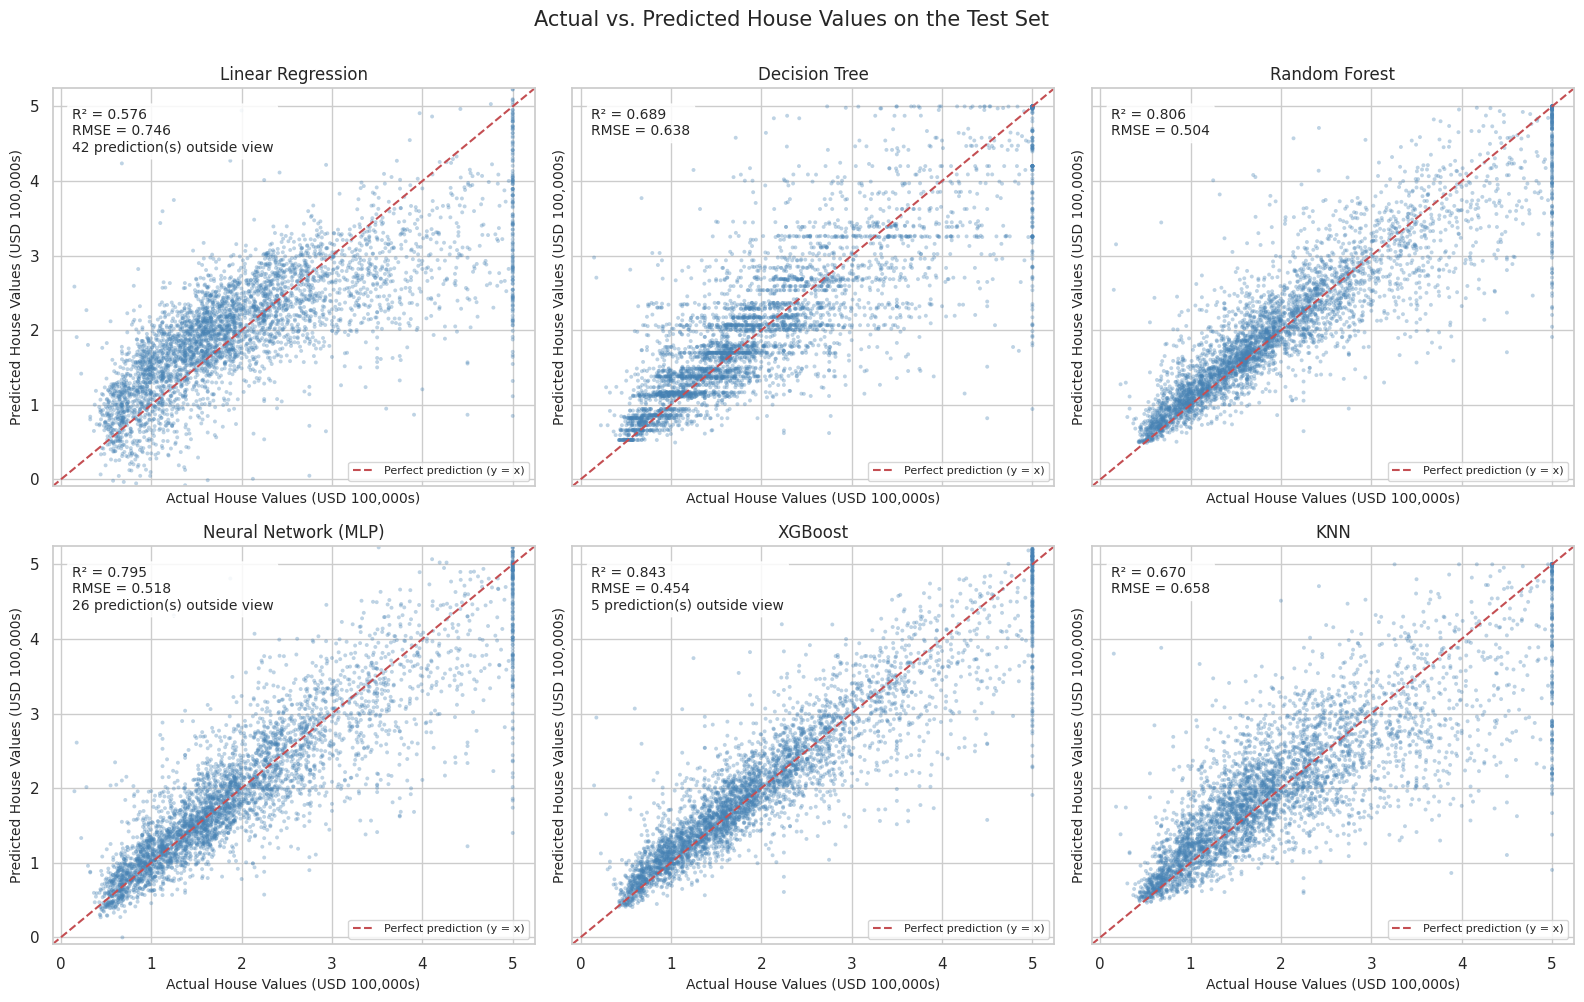

In [24]:
model_names = list(models.keys())

# Shared axis range taken from the ACTUAL target values, so a few extreme predictions
# cannot stretch the axes. Predictions outside this view are counted and reported on each panel.
margin = 0.05 * (y_test.max() - y_test.min())
axis_limits = (y_test.min() - margin, y_test.max() + margin)

fig, axes = plt.subplots(2, 3, figsize=(16, 10), sharex=True, sharey=True)
for ax, name in zip(axes.ravel(), model_names):
    pred = predictions[name]
    n_hidden = int(((pred < axis_limits[0]) | (pred > axis_limits[1])).sum())
    ax.scatter(y_test, pred, s=8, alpha=0.35, color="steelblue", edgecolor="none")
    ax.plot(axis_limits, axis_limits, "r--", linewidth=1.5, label="Perfect prediction (y = x)")
    ax.set_xlim(axis_limits)
    ax.set_ylim(axis_limits)
    ax.set_title(name)
    ax.set_xlabel("Actual House Values (USD 100,000s)")
    ax.set_ylabel("Predicted House Values (USD 100,000s)")
    note = f"R² = {results_df.loc[name, 'R²']:.3f}\nRMSE = {results_df.loc[name, 'RMSE']:.3f}"
    if n_hidden:
        note += f"\n{n_hidden} prediction(s) outside view"
    ax.text(0.04, 0.95, note, transform=ax.transAxes, va="top", fontsize=10,
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.85))
    ax.legend(loc="lower right", fontsize=8)

fig.suptitle("Actual vs. Predicted House Values on the Test Set", fontsize=15, y=1.00)
plt.tight_layout()
plt.show()

### 8.2 Model Performance Comparison

Bar charts of the test RMSE (lower is better) and test R² (higher is better). The best model in each chart is highlighted.

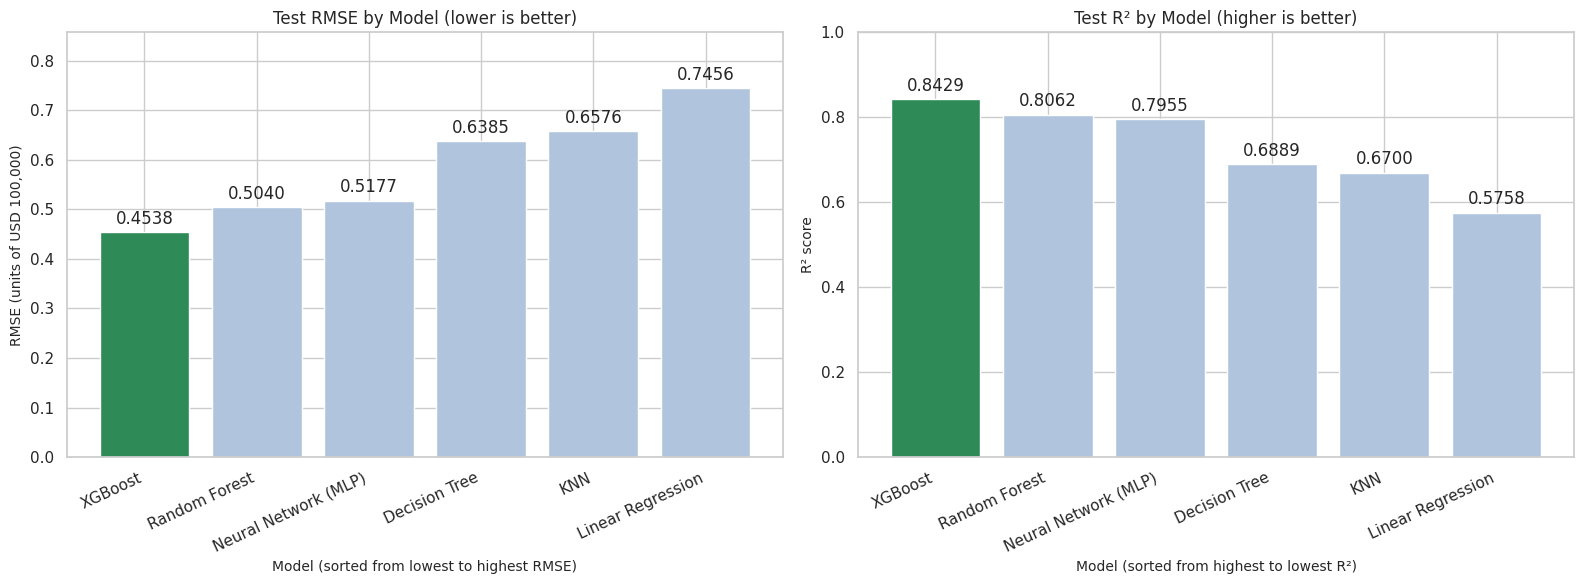

In [25]:
rmse_sorted = results_df["RMSE"].sort_values(ascending=True)
r2_sorted = results_df["R²"].sort_values(ascending=False)

def bar_colors(index, best):
    return ["seagreen" if m == best else "lightsteelblue" for m in index]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

bars = axes[0].bar(rmse_sorted.index, rmse_sorted.values, color=bar_colors(rmse_sorted.index, rmse_sorted.index[0]))
axes[0].bar_label(bars, fmt="%.4f", padding=3)
axes[0].set_title("Test RMSE by Model (lower is better)")
axes[0].set_xlabel("Model (sorted from lowest to highest RMSE)")
axes[0].set_ylabel("RMSE (units of USD 100,000)")
axes[0].set_ylim(0, rmse_sorted.max() * 1.15)

bars = axes[1].bar(r2_sorted.index, r2_sorted.values, color=bar_colors(r2_sorted.index, r2_sorted.index[0]))
axes[1].bar_label(bars, fmt="%.4f", padding=3)
axes[1].set_title("Test R² by Model (higher is better)")
axes[1].set_xlabel("Model (sorted from highest to lowest R²)")
axes[1].set_ylabel("R² score")
axes[1].set_ylim(min(0, r2_sorted.min() * 1.1), 1.0)

for ax in axes:
    ax.tick_params(axis="x", rotation=25)
    for label in ax.get_xticklabels():
        label.set_ha("right")

plt.tight_layout()
plt.show()

### 8.3 Residual Analysis

**Residual = Actual − Predicted.** Each panel plots residuals against predicted values; the dashed line marks a residual of 0 (perfect prediction).

- **Random scatter around 0 with roughly constant spread** suggests the model captured the main structure of the data and its errors are not systematically biased.
- **Curves, funnels or bands** suggest a systematic problem: a curved pattern indicates unmodelled non-linearity, a widening funnel indicates error variance that grows with the predicted value (heteroscedasticity), and a mostly positive or negative cloud indicates bias.
- A diagonal band of points is expected here because the target is capped at its maximum: for those samples the residual necessarily decreases as the prediction increases.

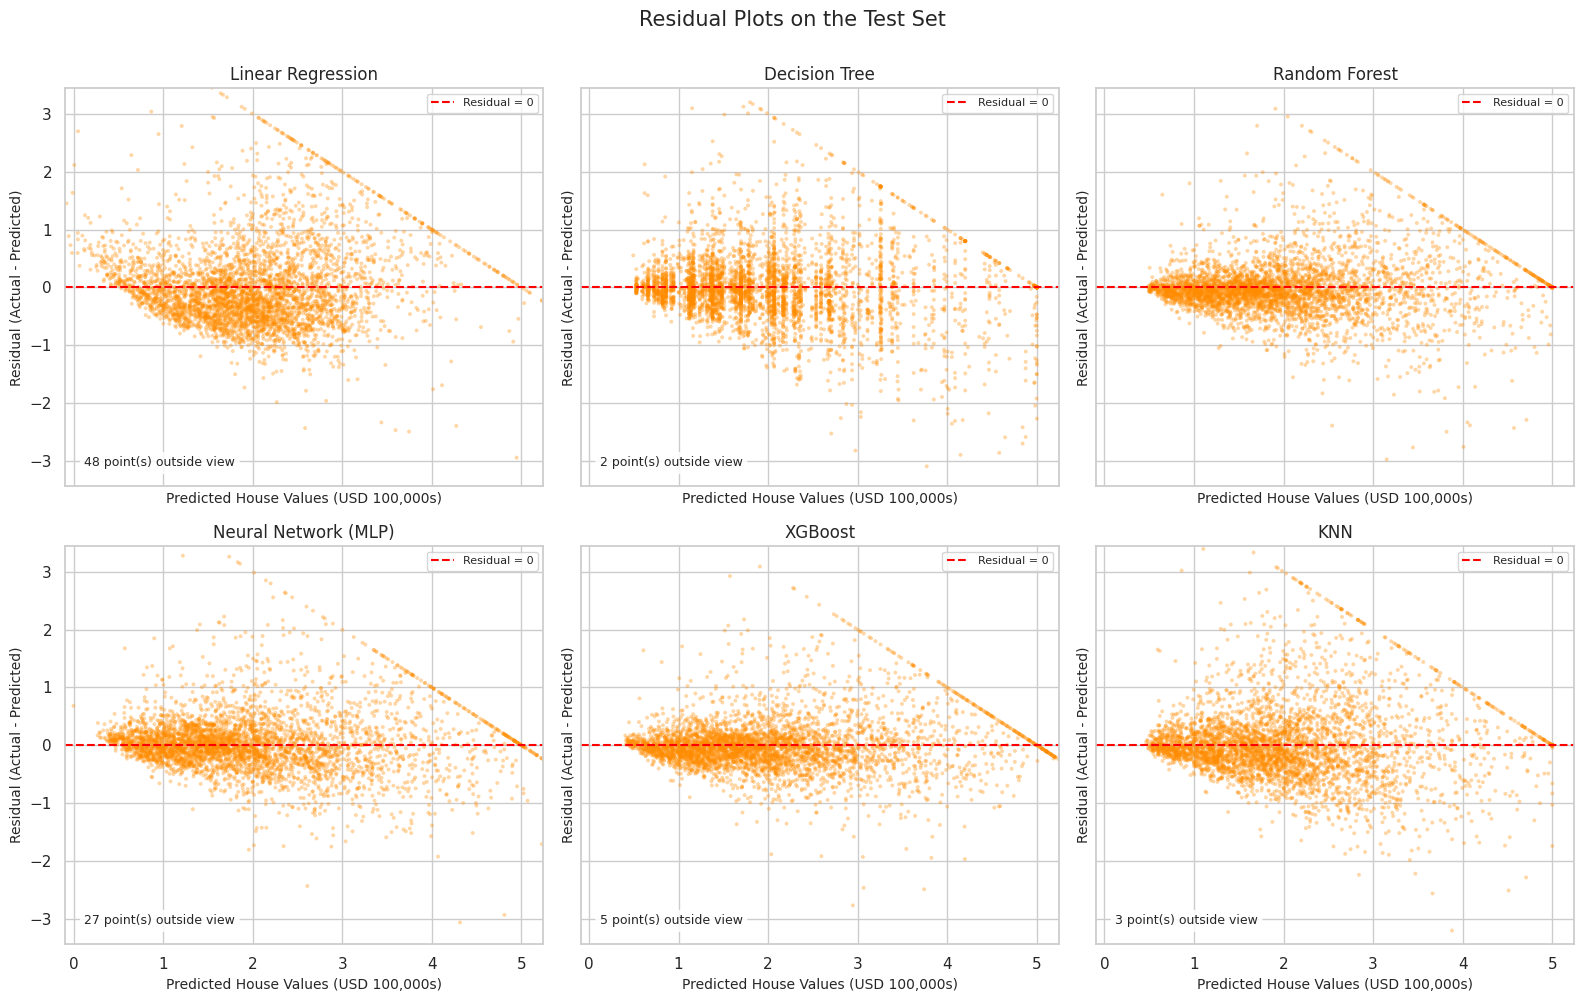

,Mean residual,Std of residuals
Model,,
XGBoost,-0.0046,0.4537
Random Forest,-0.0125,0.5038
Neural Network (MLP),0.0331,0.5166
Decision Tree,-0.0026,0.6385
KNN,0.0174,0.6574
Linear Regression,0.0035,0.7456


In [26]:
residuals = {name: y_test.to_numpy() - pred for name, pred in predictions.items()}

# Shared axes: x-range = same view as the actual-vs-predicted plots; y-range = a high percentile of
# |residual| over all models, so rare extreme errors do not squash the plots. Hidden points are counted.
VIEW_PERCENTILE = 99.9
res_all = np.concatenate([residuals[n] for n in model_names])
res_limit = np.percentile(np.abs(res_all), VIEW_PERCENTILE) * 1.1

fig, axes = plt.subplots(2, 3, figsize=(16, 10), sharex=True, sharey=True)
for ax, name in zip(axes.ravel(), model_names):
    pred, resid = predictions[name], residuals[name]
    n_hidden = int(((pred < axis_limits[0]) | (pred > axis_limits[1]) | (np.abs(resid) > res_limit)).sum())
    ax.scatter(pred, resid, s=8, alpha=0.35, color="darkorange", edgecolor="none")
    ax.axhline(0, color="red", linestyle="--", linewidth=1.5, label="Residual = 0")
    ax.set_xlim(axis_limits)
    ax.set_ylim(-res_limit, res_limit)
    ax.set_title(name)
    ax.set_xlabel("Predicted House Values (USD 100,000s)")
    ax.set_ylabel("Residual (Actual - Predicted)")
    if n_hidden:
        ax.text(0.04, 0.05, f"{n_hidden} point(s) outside view", transform=ax.transAxes, fontsize=9,
                bbox=dict(boxstyle="round", facecolor="white", alpha=0.85))
    ax.legend(loc="upper right", fontsize=8)

fig.suptitle("Residual Plots on the Test Set", fontsize=15, y=1.00)
plt.tight_layout()
plt.show()

# Numeric summary of residuals (mean close to 0 = little overall bias)
residual_summary = pd.DataFrame({
    "Mean residual": {n: r.mean() for n, r in residuals.items()},
    "Std of residuals": {n: r.std() for n, r in residuals.items()},
})
residual_summary.index.name = "Model"
with pd.option_context("display.float_format", "{:.4f}".format):
    display(residual_summary.loc[results_df.index])

### 8.4 Feature Importance (Tree-Based Models Only)

Only the three tree-based models provide a built-in `feature_importances_` attribute, so only they are shown. For tree models it measures how much each feature reduces the error across all splits (normalised to sum to 1).

Linear Regression coefficients, KNN and the MLP have no equivalent measure and are **not** plotted here. Tree-based importance is **model-specific** and describes how *that model* used the features; it must **not** be read as a causal effect of a feature on house prices. It can also be biased when features are correlated (e.g. `Latitude` and `Longitude`).

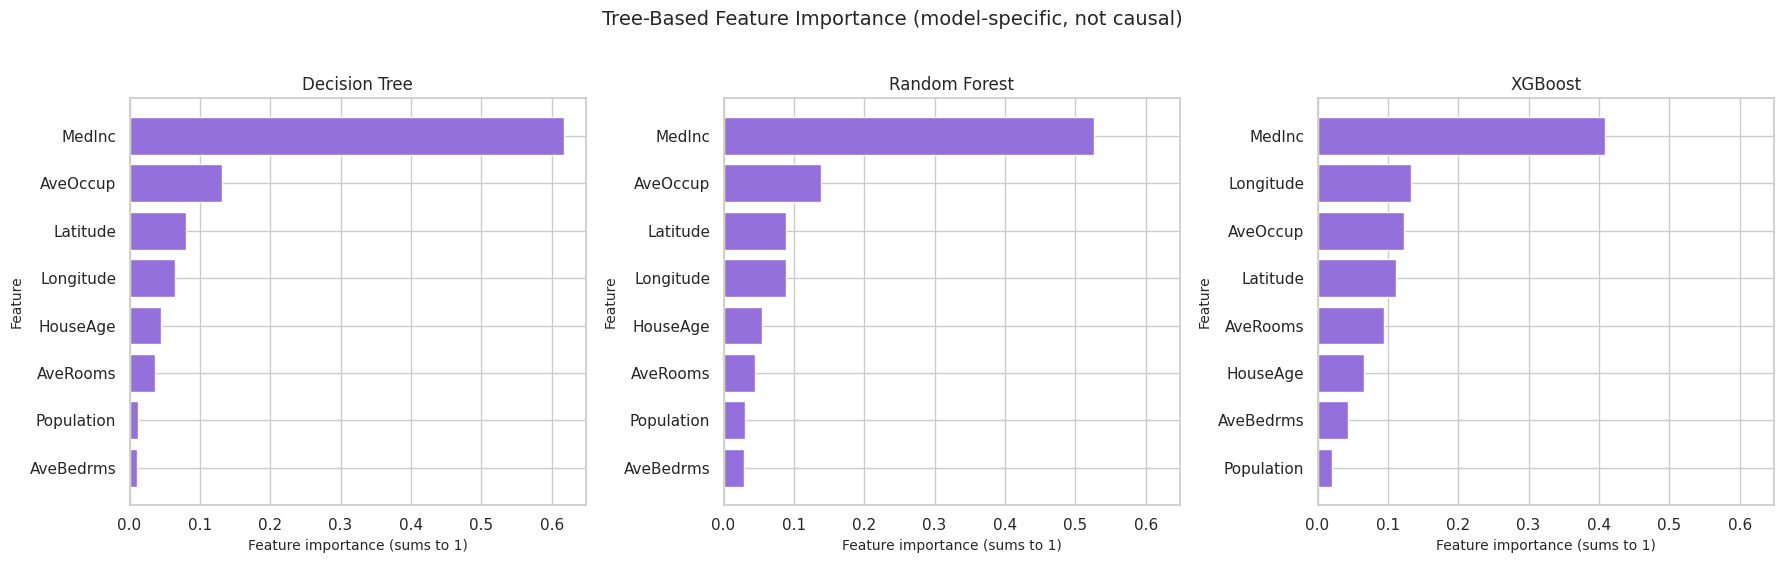

,Decision Tree,Random Forest,XGBoost
MedInc,0.6178,0.5259,0.4082
AveOccup,0.1318,0.1381,0.1230
Latitude,0.0798,0.0886,0.1112
Longitude,0.0653,0.0883,0.1325
HouseAge,0.0450,0.0544,0.0659
AveRooms,0.0369,0.0444,0.0944
Population,0.0126,0.0307,0.0212
AveBedrms,0.0107,0.0296,0.0436


In [27]:
tree_models = ["Decision Tree", "Random Forest", "XGBoost"]
importance_df = pd.DataFrame(
    {name: fitted_models[name].feature_importances_ for name in tree_models},
    index=X.columns,
)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharex=True)
for ax, name in zip(axes, tree_models):
    imp = importance_df[name].sort_values(ascending=True)
    ax.barh(imp.index, imp.values, color="mediumpurple")
    ax.set_title(f"{name}")
    ax.set_xlabel("Feature importance (sums to 1)")
    ax.set_ylabel("Feature")

fig.suptitle("Tree-Based Feature Importance (model-specific, not causal)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

with pd.option_context("display.float_format", "{:.4f}".format):
    display(importance_df.sort_values("Random Forest", ascending=False))

## 9. Comparative Discussion

The discussion below is **generated by code from the metric tables computed above**, so every statement is tied to the actual results of this run. Nothing was written in advance about which model would win.

In [28]:
res = results_df                                   # unrounded, sorted by RMSE
rank = {m: i + 1 for i, m in enumerate(res.index)} # rank by RMSE (1 = best)
n_models = len(res)

def usd(units):
    """Convert a value in units of USD 100,000 to a readable dollar string."""
    return f"USD {units * UNIT_USD:,.0f}"

lines = []

# --- Best per metric
lines.append("### Best models by metric")
lines.append(f"- **Lowest MAE:** {best_mae_model} - MAE = {res.loc[best_mae_model, 'MAE']:.4f} "
             f"(about {usd(res.loc[best_mae_model, 'MAE'])} average absolute error).")
lines.append(f"- **Lowest RMSE:** {best_rmse_model} - RMSE = {res.loc[best_rmse_model, 'RMSE']:.4f} "
             f"(about {usd(res.loc[best_rmse_model, 'RMSE'])}).")
lines.append(f"- **Highest R²:** {best_r2_model} - R² = {res.loc[best_r2_model, 'R²']:.4f} "
             f"(explains {100 * res.loc[best_r2_model, 'R²']:.1f}% of the variance in the test target).")
if len({best_mae_model, best_rmse_model, best_r2_model}) == 1:
    lines.append(f"- The same model, **{best_rmse_model}**, ranks first on MAE, RMSE and R², so the ranking is consistent across metrics.")
else:
    lines.append("- The best model differs between metrics, which means the rankings depend on how errors are weighted (RMSE penalises large errors more than MAE).")

# --- Overall ranking
order = " > ".join(f"{m} ({res.loc[m, 'RMSE']:.4f})" for m in res.index)
lines.append("\n### Overall ranking (by test RMSE, best first)")
lines.append(f"{order}")

# --- Linear vs non-linear
lin = "Linear Regression"
nonlinear = [m for m in res.index if m != lin]
better_than_lin = [m for m in nonlinear if res.loc[m, "RMSE"] < res.loc[lin, "RMSE"]]
best_nl = min(nonlinear, key=lambda m: res.loc[m, "RMSE"])
change = 100 * (res.loc[lin, "RMSE"] - res.loc[best_nl, "RMSE"]) / res.loc[lin, "RMSE"]
lines.append("\n### Linear Regression vs. non-linear models")
lines.append(f"- Linear Regression ranked **{rank[lin]} of {n_models}** (RMSE = {res.loc[lin, 'RMSE']:.4f}, R² = {res.loc[lin, 'R²']:.4f}).")
if better_than_lin:
    lines.append(f"- {len(better_than_lin)} of the {len(nonlinear)} non-linear models achieved a lower RMSE than Linear Regression. "
                 f"The best of them, {best_nl}, reduced RMSE by {change:.1f}% relative to Linear Regression. "
                 "This suggests that the relationship between the features and house value contains non-linear effects and feature interactions that a purely linear model cannot represent.")
else:
    lines.append("- No non-linear model achieved a lower RMSE than Linear Regression in this experiment, so the added flexibility did not help under the chosen fixed settings.")

# --- Decision tree and over-fitting
OVERFIT_GAP_THRESHOLD = 0.05   # wording threshold only: R² gap above this is described as notable over-fitting
dt = generalisation_df.loc["Decision Tree"]
best_ens = min(["Random Forest", "XGBoost"], key=lambda m: res.loc[m, "RMSE"])
rel = 100 * (res.loc["Decision Tree", "RMSE"] - res.loc[best_ens, "RMSE"]) / res.loc[best_ens, "RMSE"]
gaps = generalisation_df.loc[tree_models, "R² gap (train - test)"]
largest_gap_model = gaps.idxmax()
lines.append("\n### Decision Tree and over-fitting")
lines.append(f"- Decision Tree: train R² = {dt['Train R²']:.4f}, test R² = {dt['Test R²']:.4f} (gap = {dt['R² gap (train - test)']:.4f}). "
             f"Random Forest gap = {gaps['Random Forest']:.4f}; XGBoost gap = {gaps['XGBoost']:.4f}.")
direction = "higher" if rel > 0 else "lower"
lines.append(f"- The Decision Tree's test RMSE is {abs(rel):.1f}% {direction} than that of the better ensemble ({best_ens}).")
if dt["R² gap (train - test)"] > OVERFIT_GAP_THRESHOLD and rel > 0:
    lines.append("- **Conclusion:** the Decision Tree shows signs of over-fitting / high variance: it fits the training data noticeably better than the test data and is outperformed on the test set by the ensemble.")
else:
    lines.append("- **Conclusion:** evidence of over-fitting for the Decision Tree is limited under this configuration (depth and leaf size were restricted).")
lines.append(f"- Among the three tree-based models, {largest_gap_model} has the largest train-test R² gap. Ensembles can also fit the training data very closely, so test error, not the gap alone, is the deciding criterion.")

# --- KNN
knn_rmse = res.loc["KNN", "RMSE"]
knn_vs_lin = "lower" if knn_rmse < res.loc[lin, "RMSE"] else "higher"
lines.append("\n### K-Nearest Neighbors")
lines.append(f"- KNN ranked **{rank['KNN']} of {n_models}** (RMSE = {knn_rmse:.4f}, R² = {res.loc['KNN', 'R²']:.4f}); its RMSE is {knn_vs_lin} than Linear Regression's.")
lines.append("- Possible explanations: KNN predicts locally and needs no assumed functional form, which can suit data with strong geographic structure (latitude/longitude), "
             "but with standardised features every dimension contributes equally to the distance, so weakly informative features add noise to the neighbour search, "
             "and K = 5 was fixed rather than tuned.")

# --- MLP
mlp_rmse = res.loc["Neural Network (MLP)", "RMSE"]
stop_text = (f"training stopped after {mlp_n_iter} epochs (limit {mlp_max_iter}) because the internal validation score stopped improving"
             if mlp_stopped_early and not mlp_convergence_warning
             else f"training reached the epoch limit ({mlp_max_iter}) without meeting the stopping criterion, so it may not have fully converged")
mlp_vs = [m for m in res.index if m != "Neural Network (MLP)" and res.loc[m, "RMSE"] > mlp_rmse]
lines.append("\n### Neural network (MLP)")
lines.append(f"- The MLP ranked **{rank['Neural Network (MLP)']} of {n_models}** (RMSE = {mlp_rmse:.4f}, R² = {res.loc['Neural Network (MLP)', 'R²']:.4f}); {stop_text}.")
lines.append(f"- It outperformed {len(mlp_vs)} of the other {n_models - 1} models" + (f" ({', '.join(mlp_vs)})." if mlp_vs else "."))
lines.append("- MLP results are sensitive to architecture, learning rate, regularisation and initialisation; no tuning was done here, so this result is a baseline for this configuration.")

# --- Ensembles
ensembles = ["Random Forest", "XGBoost"]
others = [m for m in res.index if m not in ensembles]
ens_mean = res.loc[ensembles, "RMSE"].mean()
oth_mean = res.loc[others, "RMSE"].mean()
lines.append("\n### Ensemble models on structured tabular data")
lines.append(f"- Mean test RMSE of the ensemble models (Random Forest, XGBoost) = {ens_mean:.4f}; mean RMSE of the other four models = {oth_mean:.4f}.")
if ens_mean < oth_mean:
    lines.append("- On average the ensembles were more accurate in this experiment. A plausible explanation is that tree ensembles handle non-linear relationships and interactions between features "
                 "without feature scaling, are relatively robust to outliers and skewed features, and reduce variance (bagging) or bias (boosting) compared with a single model.")
else:
    lines.append("- The ensembles did not outperform the other models on average in this experiment, so no general advantage for ensembles can be claimed from these results.")

display(Markdown("\n".join(lines)))

### Best models by metric
- **Lowest MAE:** XGBoost - MAE = 0.2993 (about USD 29,925 average absolute error).
- **Lowest RMSE:** XGBoost - RMSE = 0.4538 (about USD 45,376).
- **Highest R²:** XGBoost - R² = 0.8429 (explains 84.3% of the variance in the test target).
- The same model, **XGBoost**, ranks first on MAE, RMSE and R², so the ranking is consistent across metrics.

### Overall ranking (by test RMSE, best first)
XGBoost (0.4538) > Random Forest (0.5040) > Neural Network (MLP) (0.5177) > Decision Tree (0.6385) > KNN (0.6576) > Linear Regression (0.7456)

### Linear Regression vs. non-linear models
- Linear Regression ranked **6 of 6** (RMSE = 0.7456, R² = 0.5758).
- 5 of the 5 non-linear models achieved a lower RMSE than Linear Regression. The best of them, XGBoost, reduced RMSE by 39.1% relative to Linear Regression. This suggests that the relationship between the features and house value contains non-linear effects and feature interactions that a purely linear model cannot represent.

### Decision Tree and over-fitting
- Decision Tree: train R² = 0.8201, test R² = 0.6889 (gap = 0.1312). Random Forest gap = 0.1680; XGBoost gap = 0.0754.
- The Decision Tree's test RMSE is 40.7% higher than that of the better ensemble (XGBoost).
- **Conclusion:** the Decision Tree shows signs of over-fitting / high variance: it fits the training data noticeably better than the test data and is outperformed on the test set by the ensemble.
- Among the three tree-based models, Random Forest has the largest train-test R² gap. Ensembles can also fit the training data very closely, so test error, not the gap alone, is the deciding criterion.

### K-Nearest Neighbors
- KNN ranked **5 of 6** (RMSE = 0.6576, R² = 0.6700); its RMSE is lower than Linear Regression's.
- Possible explanations: KNN predicts locally and needs no assumed functional form, which can suit data with strong geographic structure (latitude/longitude), but with standardised features every dimension contributes equally to the distance, so weakly informative features add noise to the neighbour search, and K = 5 was fixed rather than tuned.

### Neural network (MLP)
- The MLP ranked **3 of 6** (RMSE = 0.5177, R² = 0.7955); training stopped after 103 epochs (limit 500) because the internal validation score stopped improving.
- It outperformed 3 of the other 5 models (Decision Tree, KNN, Linear Regression).
- MLP results are sensitive to architecture, learning rate, regularisation and initialisation; no tuning was done here, so this result is a baseline for this configuration.

### Ensemble models on structured tabular data
- Mean test RMSE of the ensemble models (Random Forest, XGBoost) = 0.4789; mean RMSE of the other four models = 0.6398.
- On average the ensembles were more accurate in this experiment. A plausible explanation is that tree ensembles handle non-linear relationships and interactions between features without feature scaling, are relatively robust to outliers and skewed features, and reduce variance (bagging) or bias (boosting) compared with a single model.

In [29]:
# ---- Accuracy vs. complexity vs. interpretability vs. computational cost ----
INTERPRETABILITY = {   # qualitative, general properties of each algorithm
    "Linear Regression":    "High (one coefficient per feature)",
    "Decision Tree":        "Medium-high (readable if-then rules)",
    "Random Forest":        "Low-medium (200 trees; importance scores only)",
    "Neural Network (MLP)": "Low (black box)",
    "XGBoost":              "Low-medium (300 trees; importance scores only)",
    "KNN":                  "Medium (instance-based, no global model)",
}

tradeoff_df = results_df[["RMSE", "R²"]].copy()
tradeoff_df["Fit time (s)"] = pd.Series(fit_times)
tradeoff_df["Interpretability"] = pd.Series(INTERPRETABILITY)

with pd.option_context("display.float_format", "{:.4f}".format, "display.max_colwidth", None):
    display(tradeoff_df)

fastest = tradeoff_df["Fit time (s)"].idxmin()
slowest = tradeoff_df["Fit time (s)"].idxmax()
display(Markdown(
    f"**Trade-offs in this run.** {fastest} was the fastest to train ({tradeoff_df.loc[fastest, 'Fit time (s)']:.2f} s) and "
    f"{slowest} the slowest ({tradeoff_df.loc[slowest, 'Fit time (s)']:.2f} s). "
    f"The most accurate model by RMSE, **{best_rmse_model}**, took {tradeoff_df.loc[best_rmse_model, 'Fit time (s)']:.2f} s to train and its interpretability is rated "
    f"'{INTERPRETABILITY[best_rmse_model]}', compared with '{INTERPRETABILITY[lin]}' for Linear Regression. "
    "In general, more flexible models can capture more structure but are harder to explain, slower to train or predict, and more sensitive to hyper-parameters; "
    "simpler models are faster and easier to justify but may underfit. Training times depend on the hardware and are indicative only."
))

,RMSE,R²,Fit time (s),Interpretability
Model,,,,
XGBoost,0.4538,0.8429,3.3671,Low-medium (300 trees; importance scores only)
Random Forest,0.5040,0.8062,32.2679,Low-medium (200 trees; importance scores only)
Neural Network (MLP),0.5177,0.7955,19.4446,Low (black box)
Decision Tree,0.6385,0.6889,0.1991,Medium-high (readable if-then rules)
KNN,0.6576,0.6700,0.0309,"Medium (instance-based, no global model)"
Linear Regression,0.7456,0.5758,0.0231,High (one coefficient per feature)


**Trade-offs in this run.** Linear Regression was the fastest to train (0.02 s) and Random Forest the slowest (32.27 s). The most accurate model by RMSE, **XGBoost**, took 3.37 s to train and its interpretability is rated 'Low-medium (300 trees; importance scores only)', compared with 'High (one coefficient per feature)' for Linear Regression. In general, more flexible models can capture more structure but are harder to explain, slower to train or predict, and more sensitive to hyper-parameters; simpler models are faster and easier to justify but may underfit. Training times depend on the hardware and are indicative only.

## 10. Final Conclusion

The conclusion below is also generated from the computed results: the winner is selected programmatically (lowest test RMSE) and is cross-checked against MAE and R².

In [30]:
winner = results_df["RMSE"].idxmin()
w = results_df.loc[winner]

REASONS = {   # cautious, general explanations (not tested in this notebook)
    "Linear Regression":    "its linear structure appears to be sufficient for this data under the chosen settings, so extra flexibility did not reduce test error",
    "Decision Tree":        "a single restricted tree could capture non-linear effects and interactions well enough without needing scaling",
    "Random Forest":        "averaging many decorrelated trees captures non-linear effects and feature interactions while reducing the variance of a single tree",
    "Neural Network (MLP)": "stacked non-linear layers on standardised inputs can approximate complex relationships between the features and house value",
    "XGBoost":              "sequentially fitting trees to the remaining errors, with shrinkage and subsampling, can model non-linear effects and interactions while controlling over-fitting",
    "KNN":                  "local averaging in the standardised feature space can exploit the strong geographic and income structure of the data",
}

agree = {"MAE": best_mae_model == winner, "R²": best_r2_model == winner}
if all(agree.values()):
    agreement = "The same model also has the lowest MAE and the highest R², so the conclusion is consistent across all three ranking criteria."
else:
    differing = ", ".join(f"{k} ({best_mae_model if k == 'MAE' else best_r2_model})" for k, ok in agree.items() if not ok)
    agreement = f"Note that the best model differs for: {differing}; the ranking therefore depends on the metric used."

runner_up = results_df.index[1]
conclusion = f"""
### Best-performing algorithm: **{winner}**

On the held-out test set, **{winner}** achieved the lowest RMSE (**{w['RMSE']:.4f}**, about {usd(w['RMSE'])}), with MAE = **{w['MAE']:.4f}** (about {usd(w['MAE'])}) and R² = **{w['R²']:.4f}**.
{agreement} The runner-up by RMSE was {runner_up} (RMSE = {results_df.loc[runner_up, 'RMSE']:.4f}).

**Possible reason (not tested here):** {REASONS[winner]}.

**Performance vs. interpretability:** {winner} is rated '{INTERPRETABILITY[winner]}' for interpretability, whereas Linear Regression is rated '{INTERPRETABILITY[lin]}'. {"Here the most accurate model is also the easiest to interpret." if winner == lin else f"Linear Regression's RMSE was {results_df.loc[lin, 'RMSE']:.4f} versus {w['RMSE']:.4f} for {winner}, so the accuracy gain must be weighed against the loss of transparency, training cost and tuning effort."}

**Limitations.** These results apply to this dataset, this single 80:20 split (`random_state=42`) and the fixed hyper-parameters used; a different split or settings could change the ranking, especially when models are close. The target is capped at its maximum value, which limits accuracy for the most expensive districts, and no confidence intervals were computed.

**Future improvements.** (1) Use k-fold cross-validation on the training set to obtain more reliable estimates and confidence intervals; (2) tune hyper-parameters with `GridSearchCV` / `RandomizedSearchCV` on the training data only (e.g. K for KNN, depth and learning rate for XGBoost, architecture and regularisation for the MLP); (3) explore feature engineering such as location-based features; (4) evaluate additional models and error metrics.
"""
display(Markdown(conclusion))


### Best-performing algorithm: **XGBoost**

On the held-out test set, **XGBoost** achieved the lowest RMSE (**0.4538**, about USD 45,376), with MAE = **0.2993** (about USD 29,925) and R² = **0.8429**. 
The same model also has the lowest MAE and the highest R², so the conclusion is consistent across all three ranking criteria. The runner-up by RMSE was Random Forest (RMSE = 0.5040).

**Possible reason (not tested here):** sequentially fitting trees to the remaining errors, with shrinkage and subsampling, can model non-linear effects and interactions while controlling over-fitting.

**Performance vs. interpretability:** XGBoost is rated 'Low-medium (300 trees; importance scores only)' for interpretability, whereas Linear Regression is rated 'High (one coefficient per feature)'. Linear Regression's RMSE was 0.7456 versus 0.4538 for XGBoost, so the accuracy gain must be weighed against the loss of transparency, training cost and tuning effort.

**Limitations.** These results apply to this dataset, this single 80:20 split (`random_state=42`) and the fixed hyper-parameters used; a different split or settings could change the ranking, especially when models are close. The target is capped at its maximum value, which limits accuracy for the most expensive districts, and no confidence intervals were computed.

**Future improvements.** (1) Use k-fold cross-validation on the training set to obtain more reliable estimates and confidence intervals; (2) tune hyper-parameters with `GridSearchCV` / `RandomizedSearchCV` on the training data only (e.g. K for KNN, depth and learning rate for XGBoost, architecture and regularisation for the MLP); (3) explore feature engineering such as location-based features; (4) evaluate additional models and error metrics.
